**Data Cleaning (my extension, added after the assigned worksheet): fixed encoding, handled missing Cuisines values, checked duplicates, and created a rated-only dataset.**

Task_1: Top Cuisines
Determine the top three most
common cuisines in the dataset.
Calculate
the
percentage
of
restaurants that serve each of the top
cuisines

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("Dataset .csv")
df["City"] = df["City"].str.replace("\ufffd\ufffdstanbul", "Istanbul", regex=False)
df["City"] = df["City"].str.replace(r"^Bras.{1,3}lia$", "Brasília", regex=True)
df["City"] = df["City"].str.replace(r"^S.{1,3}o Paulo$", "São Paulo", regex=True)

# check: should print an empty Series (no corrupted city names left)
print(df[df["City"].str.contains("\ufffd", na=False)]["City"].value_counts())

Series([], Name: count, dtype: int64)


In [ ]:
print(df[df["City"].str.contains("stanbul")]["City"].unique())
print(df.select_dtypes("object").apply(lambda s: s.str.contains("\ufffd", na=False).sum()).loc[lambda s: s > 0])

['Istanbul']
Restaurant Name     103
Address              89
Locality             34
Locality Verbose     66
Cuisines              2
Currency             80
dtype: int64


In [ ]:
print(df[df["City"].str.contains("\ufffd", na=False)]["City"].value_counts())

Series([], Name: count, dtype: int64)


In [ ]:
import os

print(os.listdir())

['.config', 'Dataset .csv', 'sample_data']


In [ ]:

df["Cuisines"] = df["Cuisines"].fillna("Unknown")      # handles the 9 missing values


In [ ]:
print(df.duplicated().sum())  # duplicate check

0


In [ ]:
df_rated = df[df["Aggregate rating"] > 0]              # excludes unrated restaurants

In [ ]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [ ]:
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [ ]:
df.shape

(9551, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9551 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [ ]:
df.head(2)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591


In [ ]:
df["City"]

,City
0,Makati City
1,Makati City
2,Mandaluyong City
3,Mandaluyong City
4,Mandaluyong City
...,...
9546,Istanbul
9547,Istanbul
9548,Istanbul
9549,Istanbul


In [ ]:
df["City"].nunique()

141

In [ ]:
df["City"].value_counts()

,count
City,
New Delhi,5473
Gurgaon,1118
Noida,1080
Faridabad,251
Ghaziabad,25
...,...
Lakes Entrance,1
Mohali,1
Panchkula,1


In [ ]:
df["City"].value_counts().head(3)

,count
City,
New Delhi,5473
Gurgaon,1118
Noida,1080


In [ ]:
top=df["Cuisines"].value_counts().head(3)

In [ ]:
print(top)

Cuisines
North Indian             936
North Indian, Chinese    511
Fast Food                354
Name: count, dtype: int64


In [ ]:
percetage=top/len(df)*100


In [ ]:
print(percetage)

Cuisines
North Indian             9.800021
North Indian, Chinese    5.350225
Fast Food                3.706418
Name: count, dtype: float64


Task_2: City Analysis
Identify the city with the highest number
of restaurants in the dataset.
Calculate
the average rating for
restaurants in each city.
Determine the city with the highest
average rating

In [ ]:
import os

print(os.listdir())

['.config', 'Dataset .csv', 'sample_data']


In [ ]:
highest_city=df["City"].value_counts().head(1)
print(highest_city)

City
New Delhi    5473
Name: count, dtype: int64


In [ ]:
avg=df.groupby("City")["Aggregate rating"].mean()
print(avg)


City
Abu Dhabi          4.300000
Agra               3.965000
Ahmedabad          4.161905
Albany             3.555000
Allahabad          3.395000
                     ...   
Waterloo           3.650000
Weirton            3.900000
Wellington City    4.250000
Winchester Bay     3.200000
Yorkton            3.300000
Name: Aggregate rating, Length: 141, dtype: float64


In [ ]:
high=avg.sort_values(ascending=False)
print(high)

City
Inner City          4.900000
Quezon City         4.800000
Makati City         4.650000
Pasig City          4.633333
Mandaluyong City    4.625000
                      ...   
New Delhi           2.438845
Montville           2.400000
Mc Millan           2.400000
Noida               2.036204
Faridabad           1.866932
Name: Aggregate rating, Length: 141, dtype: float64


In [ ]:
high.head(1)

,Aggregate rating
City,
Inner City,4.9


In [ ]:
price_range_no=df["Price range"].value_counts()
print(price_range_no)

Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64


Task_3: Price Range Distribution
Create a histogram or bar chart to
visualize the distribution of price ranges
among the restaurants.
Calculate the percentage of restaurants
in each price range category

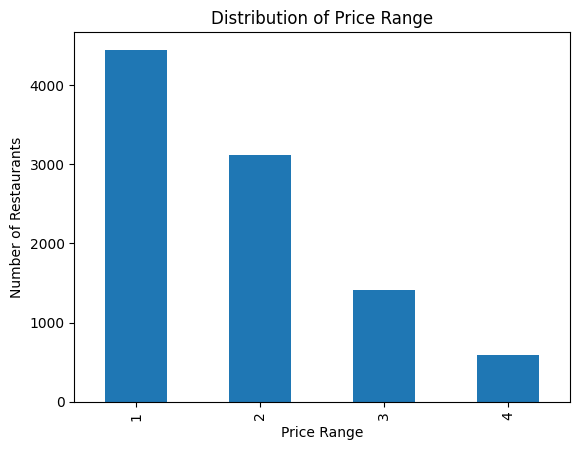

In [ ]:
import matplotlib.pyplot as plt
price_range_no.plot(kind="bar")
plt.title("Distribution of Price Range")
plt.xlabel("Price Range")
plt.ylabel("Number of Restaurants")

plt.show()


In [ ]:
percentage=(price_range_no/len(df))*100
print(percentage)

Price range
1    46.529159
2    32.593446
3    14.741912
4     6.135483
Name: count, dtype: float64


Task_4: Online Delivery
Determine the percentage of restaurants
that offer online delivery.
Compare the average ratings of restaurants
with and without online delivery


In [ ]:

delivery_count=df["Has Online delivery"].value_counts()
print(delivery_count)


Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64


In [ ]:
percentage=(delivery_count/len(df))*100
print(percentage)

Has Online delivery
No     74.337766
Yes    25.662234
Name: count, dtype: float64


In [ ]:
avg_rating=df.groupby("Has Online delivery")["Aggregate rating"].mean()
print(avg_rating)


Has Online delivery
No     2.465296
Yes    3.248837
Name: Aggregate rating, dtype: float64


By comparing the answer:
restaurants that offer online delivery have a higher average rating than not offering

In [ ]:
print("Rows, columns:", df.shape)
print("Duplicates:", df.duplicated().sum())
print("Unrated restaurants excluded:", len(df) - len(df_rated))
print("Rated restaurants:", len(df_rated))

city_stats = df_rated.groupby("City")["Aggregate rating"].agg(["mean", "count"])
print(city_stats[city_stats["count"] >= 20].sort_values("mean", ascending=False).head(5))

print(df_rated.groupby("Has Online delivery")["Aggregate rating"].agg(["mean", "count"]))

Rows, columns: (9551, 21)
Duplicates: 0
Unrated restaurants excluded: 2148
Rated restaurants: 7403
                 mean  count
City                        
London          4.535     20
Orlando         4.475     20
Rest of Hawaii  4.410     20
Tampa Bay       4.410     20
Bangalore       4.375     20
                         mean  count
Has Online delivery                 
No                   3.467433   5048
Yes                  3.381274   2355


In [ ]:
print(df[df["City"].str.contains("stanbul")]["City"].unique())

['Istanbul']


**Conclusion of the extension: 2,148 restaurants (22%) have an aggregate rating of 0 and appear to be unrated. They were concentrated among restaurants without online delivery (about 29% of that group vs 4% of delivery restaurants), which made delivery restaurants look much better rated. After excluding unrated restaurants, average ratings are close: 3.38 with delivery vs 3.47 without. Among cities with 20+ rated restaurants, London (4.54) and Orlando (4.48) rate highest.**